In [1]:

%pip install --upgrade pip
%pip install pandas numpy matplotlib seaborn scikit-learn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("All libraries imported successfully!")

   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ---------- ----------------------------- 0.5/2.0 MB 164.1 kB/s eta 0:00:09
   ---------- ----------------------------- 0.5/2.0 MB 164.1 kB/s eta 0:00:09
   ---------- --

In [2]:
import os
from pathlib import Path

# Search the entire workspace for CSV files
workspace = Path.cwd()

print("YOUR CURRENT LOCATION:", workspace)

csv_files = list(workspace.rglob("*.csv"))

print("\nCSV FILES FOUND:")

if csv_files:
    for file in csv_files:
        print(file)
else:
    print("NO CSV FILES FOUND!")

YOUR CURRENT LOCATION: d:\College_Acadmics\final\Spotify-ana-project-lr\notebook

CSV FILES FOUND:
d:\College_Acadmics\final\Spotify-ana-project-lr\notebook\spotify_churn_dataset.csv
d:\College_Acadmics\final\Spotify-ana-project-lr\notebook\spotify_churn_dataset_local_backup.csv


In [4]:
# ============================================================
#              LINEAR REGRESSION
# ============================================================
sns.set_theme(style="whitegrid")
df = pd.read_csv("spotify_churn_dataset.csv")
print("\nFirst five rows of dataset:")
print(df.head())
print("\nLast five rows of dataset:")
print(df.tail())
print("\nDataset shape (rows, columns):")
print(df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nDataset information:")
df.info()
print("\nStatistical summary:")
print(df.describe(include="all"))
print("\nData types:")
print(df.dtypes)
print("\nNumber of unique values:")
print(df.nunique())
print("everything done successfully")


First five rows of dataset:
   user_id  gender  age country subscription_type  listening_time  \
0        1  Female   54      CA              Free              26   
1        2   Other   33      DE            Family             141   
2        3    Male   38      AU           Premium             199   
3        4  Female   22      CA           Student              36   
4        5   Other   29      US            Family             250   

   songs_played_per_day  skip_rate device_type  ads_listened_per_week  \
0                    23       0.20     Desktop                     31   
1                    62       0.34         Web                      0   
2                    38       0.04      Mobile                      0   
3                     2       0.31      Mobile                      0   
4                    57       0.36      Mobile                      0   

   offline_listening  is_churned  
0                  0           1  
1                  1           0  
2           

In [5]:
print("\nMissing values in each column:")
print(df.isnull().sum())
missing_values = df.isnull().sum() # returns pandas series 
print("\n")
print("=" * 60)
print(missing_values)
print("\n")
print("=" * 60)
print(missing_values.sum())

if missing_values.sum() > 0:

    plt.figure(figsize=(10, 5))

    missing_values[missing_values > 0].sort_values().plot(
        kind="bar"
    )

    plt.title("Missing Values in Dataset")
    plt.xlabel("Columns")
    plt.ylabel("Number of Missing Values")

    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.show()
    print("SUCCESSFULLY DONE!")

print("\nNumber of duplicate rows:")
print(df.duplicated())
print(df.duplicated().sum())
df = df.drop_duplicates()
df = df.dropna(how="all")
print("\nDataset shape after removing duplicates:")
print(df.shape)


Missing values in each column:
user_id                  0
gender                   0
age                      0
country                  0
subscription_type        0
listening_time           0
songs_played_per_day     0
skip_rate                0
device_type              0
ads_listened_per_week    0
offline_listening        0
is_churned               0
dtype: int64


user_id                  0
gender                   0
age                      0
country                  0
subscription_type        0
listening_time           0
songs_played_per_day     0
skip_rate                0
device_type              0
ads_listened_per_week    0
offline_listening        0
is_churned               0
dtype: int64


0

Number of duplicate rows:
0       False
1       False
2       False
3       False
4       False
        ...  
7995    False
7996    False
7997    False
7998    False
7999    False
Length: 8000, dtype: bool
0

Dataset shape after removing duplicates:
(8000, 12)


In [6]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns.tolist()
categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("\nNumerical columns:")
print(numeric_columns)

print("\nCategorical columns:")
print(categorical_columns)

df.to_csv("spotify_cleaned.csv", index=False)
print("\nCleaned dataset saved successfully!")



Numerical columns:
['user_id', 'age', 'listening_time', 'songs_played_per_day', 'skip_rate', 'ads_listened_per_week', 'offline_listening', 'is_churned']

Categorical columns:
['gender', 'country', 'subscription_type', 'device_type']

Cleaned dataset saved successfully!


C:\Users\SARTHAK\AppData\Local\Temp\ipykernel_19584\2996636159.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


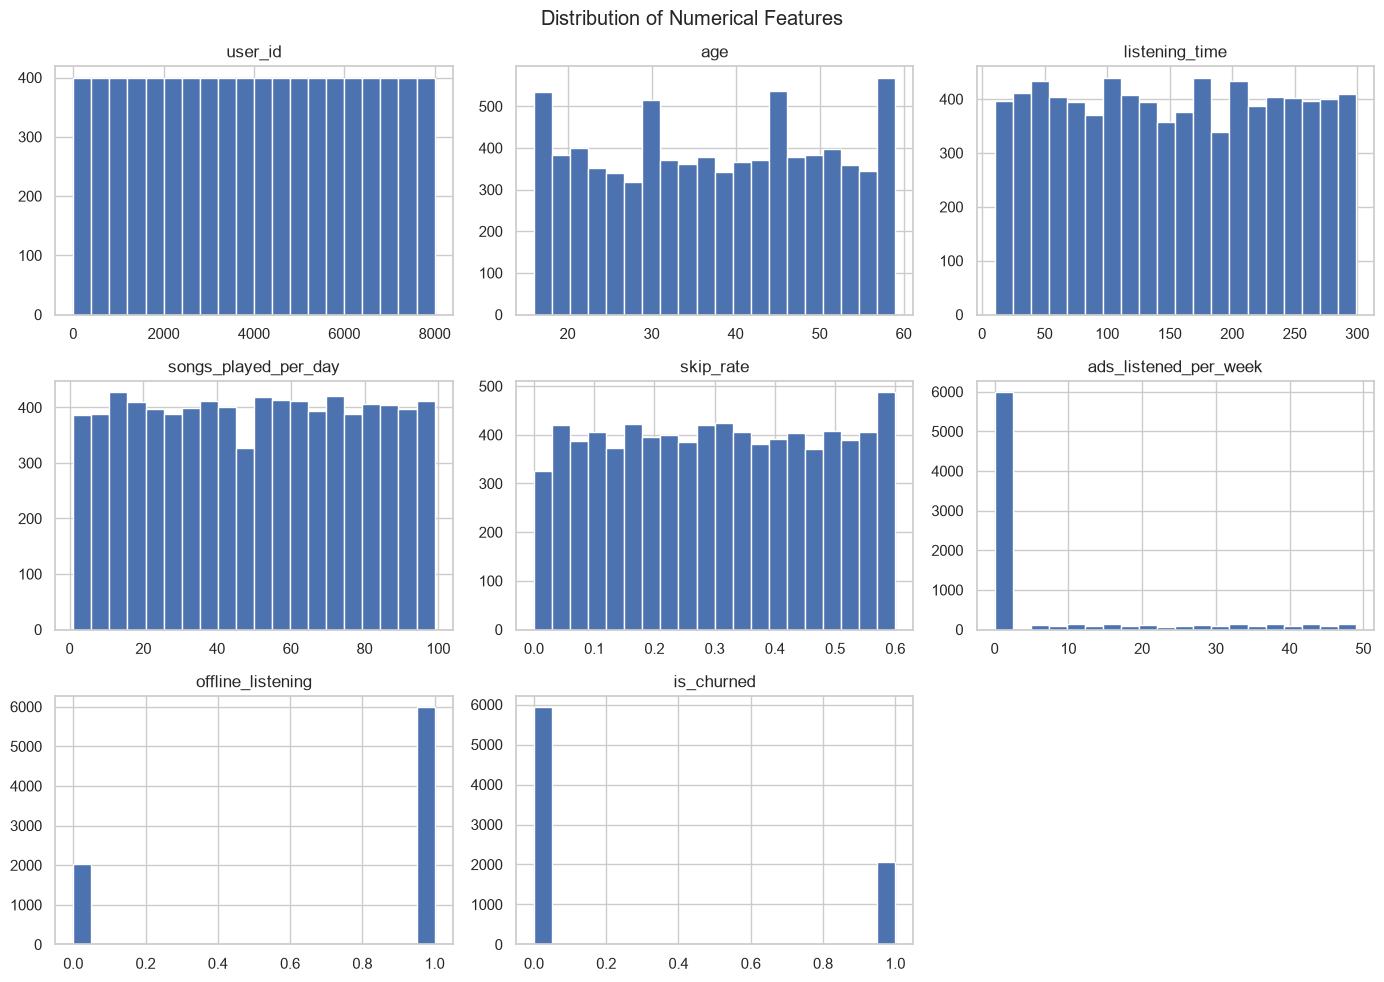

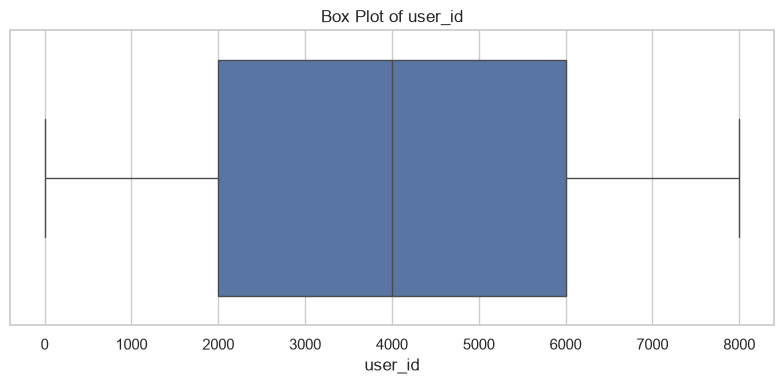

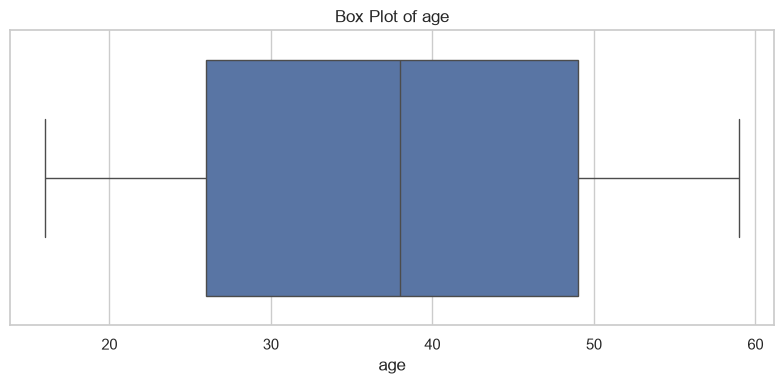

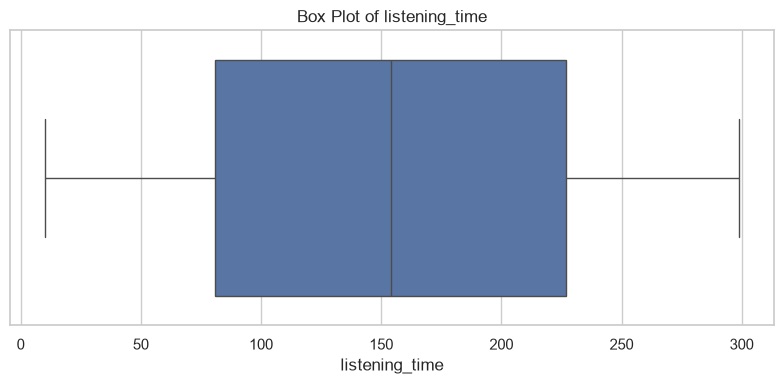

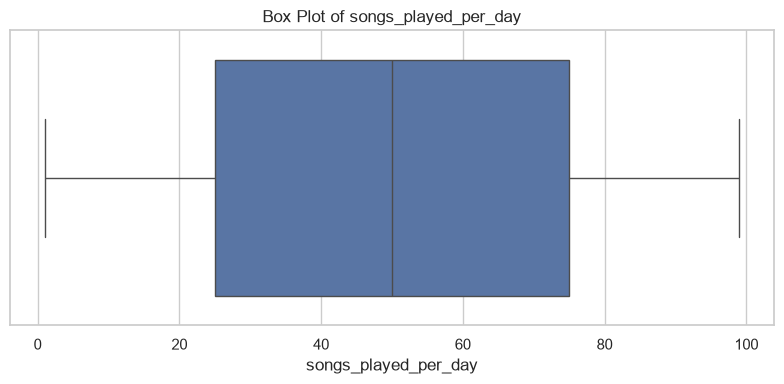

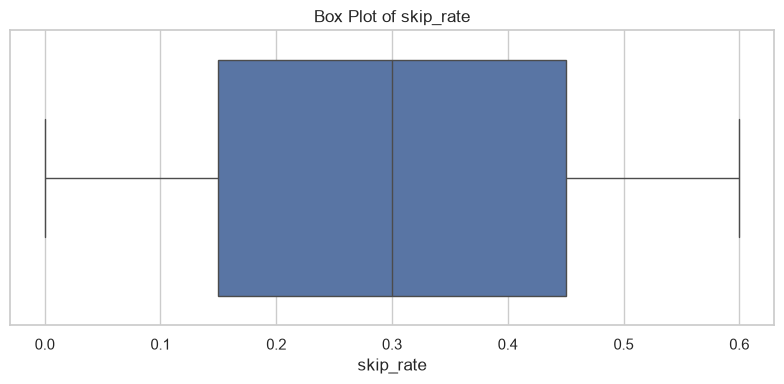

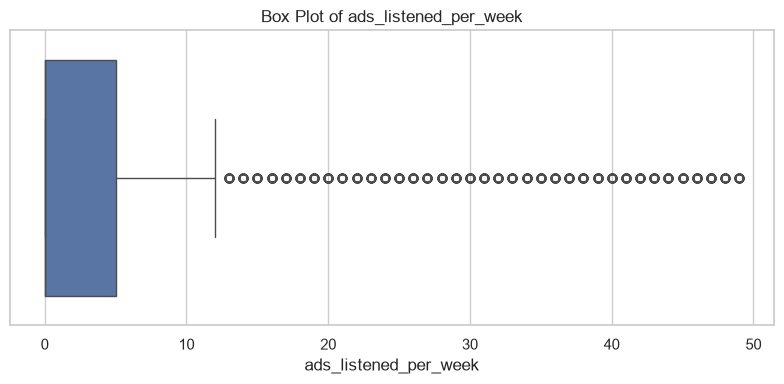

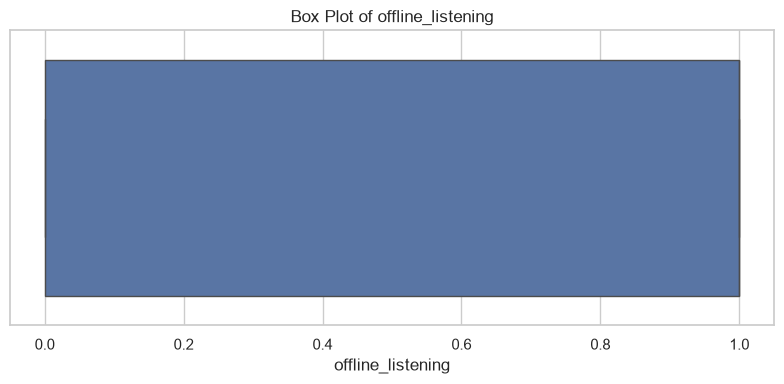

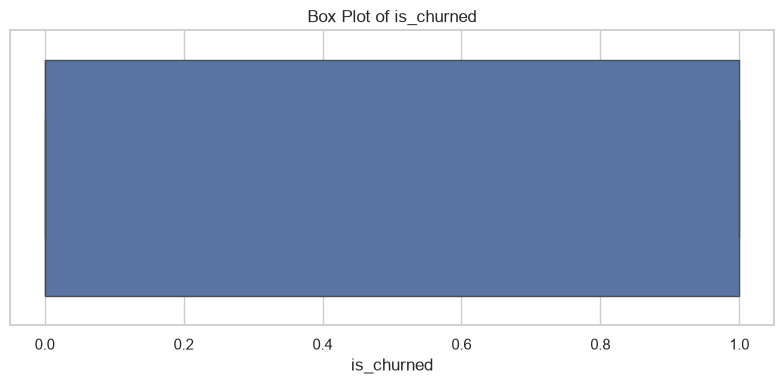

In [ ]:
# Histogram Plot

if len(numeric_columns) > 0:

    df[numeric_columns].hist(
        figsize=(14, 10),
        bins=20
    )

    plt.suptitle("Distribution of Numerical Features")
    plt.tight_layout()

    plt.show()


# Box Plot

for column in numeric_columns[:8]:

    plt.figure(figsize=(8, 4))

    sns.boxplot(x=df[column])

    plt.title("Box Plot of " + column)
    plt.xlabel(column)

    plt.tight_layout()
    

    plt.show()

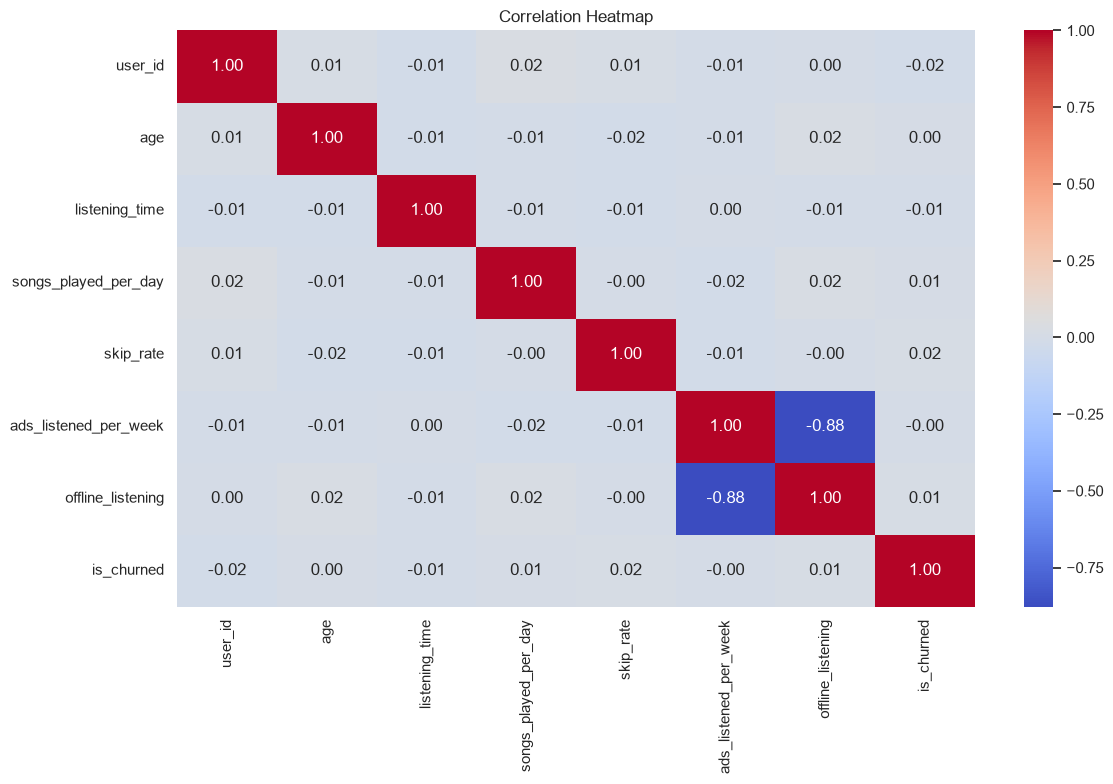

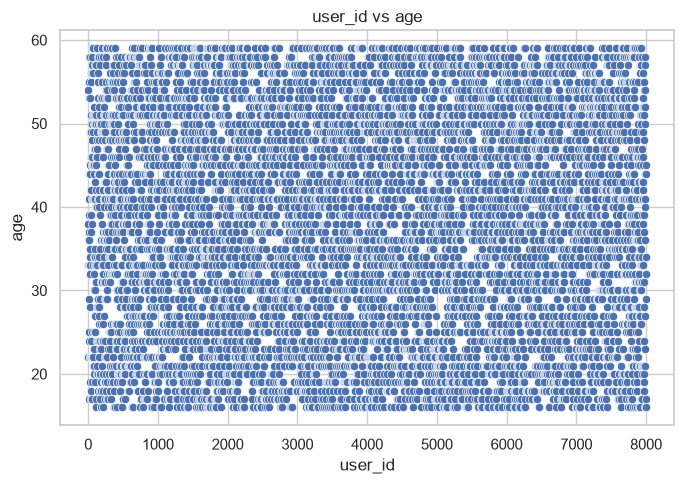

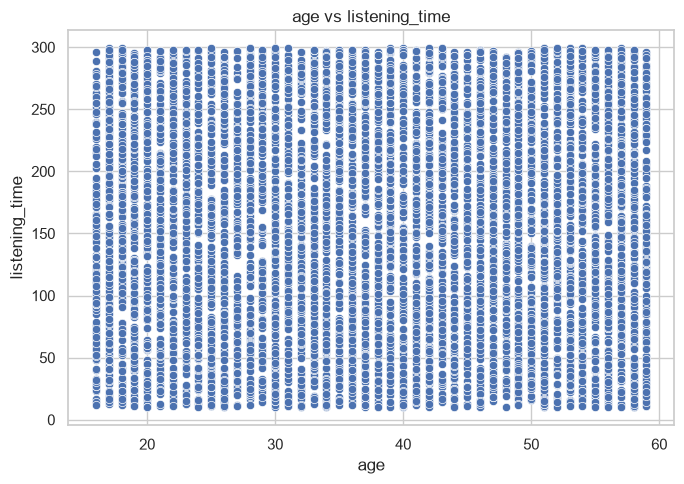

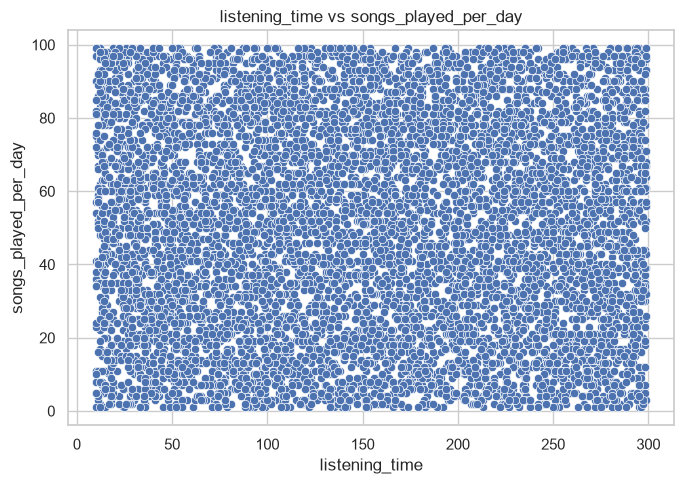

In [13]:
#block 6
# Correlation Heatmap 

if len(numeric_columns) >= 2:

    plt.figure(figsize=(12, 8))

    correlation = df[numeric_columns].corr()  # returns pandas dataframe

    sns.heatmap(
        correlation,
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )

    plt.title("Correlation Heatmap")

    plt.tight_layout()

    plt.savefig("correlation_heatmap.png")
    plt.show()

# Scatter Plot

if len(numeric_columns) >= 2:

    for i in range(min(3, len(numeric_columns) - 1)):

        x_column = numeric_columns[i]
        y_column = numeric_columns[i + 1]

        plot_data = df[[x_column, y_column]].dropna()

        if len(plot_data) > 0:

            plt.figure(figsize=(7, 5))

            sns.scatterplot(
                data=plot_data,
                x=x_column,
                y=y_column
            )

            plt.title(x_column + " vs " + y_column)

            plt.tight_layout()

            plt.savefig(
                str(i + 1) + ".png"
            )

            plt.show()


In [14]:
#block 7
# Load Cleaned Dataset 

df = pd.read_csv("spotify_cleaned.csv")

CHURN_COLUMN = None

possible_targets = [
    "churn",
    "churned",
    "is_churned",
    "customer_churn",
    "churn_status"
]

if CHURN_COLUMN is None:

    for column in possible_targets:

        if column in df.columns:

            CHURN_COLUMN = column
            break


if CHURN_COLUMN is None:

    raise ValueError(
        "Churn column not found. Set CHURN_COLUMN manually."
    )


print("\nSelected churn column:", CHURN_COLUMN)


df = df.dropna(subset=[CHURN_COLUMN]).copy()

target_values = (
    df[CHURN_COLUMN]
    .astype(str)
    .str.strip()
    .str.lower()
)

positive_values = [
    "1", "yes", "true", "churn", "churned"
]

negative_values = [
    "0", "no", "false", "not churn", "not churned", "retained"
]

unique_values = target_values.unique().tolist()


Selected churn column: is_churned


In [24]:
#block 8
if set(unique_values).issubset(
    set(positive_values + negative_values)
):

    y = target_values.isin(positive_values).astype(int)

elif len(unique_values) == 2:

    print("Target categories:", unique_values)
    print("Second category is treated as positive.")

    y = (target_values == unique_values[1]).astype(int)

else:

    raise ValueError(
        "Churn target must have exactly two categories."
    )


if y.nunique() != 2:

    raise ValueError(
        "Both churn classes must be present in the dataset."
    )

# Prepare Input Features 
X = df.drop(columns=[CHURN_COLUMN])

id_columns = [
    column for column in X.columns
    if column.lower() in [
        "id", "user_id", "customer_id", "index"
    ]
]
print("everything done successfully1")

everything done successfully1


In [25]:
#block 9
X = X.drop(columns=id_columns)

numeric_columns = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

if len(numeric_columns) + len(categorical_columns) == 0:

    raise ValueError("No usable input features found.")


# Data Preprocessing 

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numerical", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])


# Create Logistic Regression Model 

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])
print("everything done successfully1")

everything done successfully1


C:\Users\SARTHAK\AppData\Local\Temp\ipykernel_19584\3905304901.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(


In [26]:
#block 10
# Split Dataset 

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)


# Train Model 

model.fit(X_train, y_train)

print("\nLogistic Regression model trained successfully!")



# Make Predictions

y_pred = model.predict(X_test)

y_probability = model.predict_proba(X_test)[:, 1]


# Evaluate Model 

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_probability
)

print("\nLOGISTIC REGRESSION RESULTS")
print("---------------------------")

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("ROC-AUC:", roc_auc)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)



Training data shape: (6400, 10)
Testing data shape: (1600, 10)

Logistic Regression model trained successfully!

LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy: 0.74125
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
ROC-AUC: 0.49662935536166714

Classification Report:
              precision    recall  f1-score   support

           0       0.74      1.00      0.85      1186
           1       0.00      0.00      0.00       414

    accuracy                           0.74      1600
   macro avg       0.37      0.50      0.43      1600
weighted avg       0.55      0.74      0.63      1600



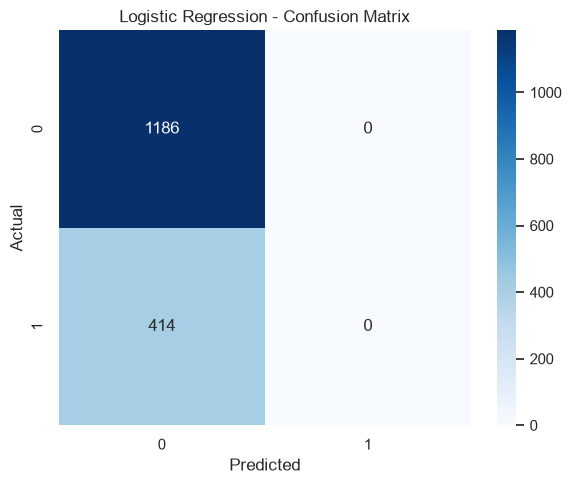

In [27]:
#block 11
# Saving Results

logistic_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC AUC"
    ],
    "Value": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

logistic_results.to_csv(
    "logistic_results.csv",
    index=False
)

logistic_predictions = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Probability": y_probability
})

logistic_predictions.to_csv(
    "logistic_predictions.csv",
    index=False
)


# Confusion Matrix 

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()

plt.savefig("member2_confusion_matrix.png")
plt.show()


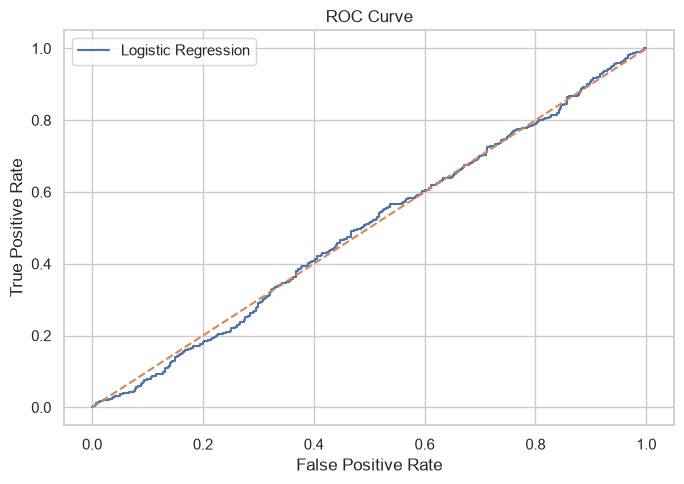

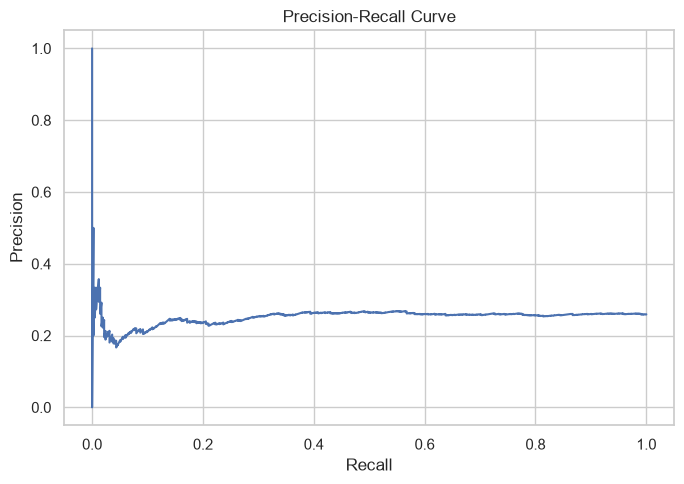

In [28]:
#block 12
# ROC Curve 

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_probability
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label="Logistic Regression"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()
plt.tight_layout()

plt.savefig("member2_roc_curve.png")
plt.show()


# Precision-Recall Curve 

precision_values, recall_values, thresholds = (
    precision_recall_curve(y_test, y_probability)
)

plt.figure(figsize=(7, 5))

plt.plot(
    recall_values,
    precision_values
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")

plt.tight_layout()

plt.show()